# 05 · Tree ensembles — Flight Price (Regression)
Random Forest and XGBoost (allowed by the TA on 11 Oct), then equal-weight averages with Ridge.

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the clean data.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

from src import evaluate
from src.regression import preprocess as pp
from src.regression.models import FloorRegressor

warnings.filterwarnings("ignore", message="Found unknown categories")
TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

X, y, X_test, test_ids, sample_sub = pp.load_clean()
RAW = list(X.columns)
print("X", X.shape, "| X_test", X_test.shape)

X (15167, 10) | X_test (3898, 10)


Helpers: CV logging and the Ridge model from notebook 04.

In [3]:
def run(name, model, params=None, notes=""):
    folds = evaluate.cross_validate(model, X, y, TASK, name, params=params, notes=notes)
    print(f"{name:28s} CV R² {folds.r2.mean():.4f} ± {folds.r2.std():.4f} | train R² {folds.train_r2.mean():.4f}"
          f" | RMSE ₹{folds.rmse.mean():,.0f}")
    return folds

def ridge_flight(alpha=3):
    features = ColumnTransformer([
        ("poly", make_pipeline(pp.make_preprocessor(), PolynomialFeatures(2, include_bias=False)), RAW),
        ("flight", OneHotEncoder(handle_unknown="ignore"), ["flight_key"]),
    ])
    return FloorRegressor(make_pipeline(FunctionTransformer(pp.add_flight_key), features, Ridge(alpha=alpha)))

Tree features: integer codes, no scaling (`TreeEncoder`).

In [4]:
pp.TreeEncoder().fit(X).transform(X).head()

,airline,flight,flight_key,source_city,destination_city,departure_time,arrival_time,flight_class,stops,duration,days_left
0,15.0,850.0,1287.0,3.0,5.0,2.0,5.0,1.0,0,2.92,18
1,8.0,84.0,102.0,2.0,5.0,5.0,5.0,1.0,0,1.33,38
2,15.0,677.0,969.0,4.0,5.0,2.0,5.0,0.0,0,2.08,13
3,8.0,421.0,579.0,4.0,3.0,0.0,2.0,1.0,0,2.25,5
4,8.0,55.0,73.0,1.0,5.0,2.0,5.0,1.0,1,4.83,21


## Random Forest — number of trees

In [5]:
def forest(n_estimators=300, max_features=0.5, min_samples_leaf=2):
    return make_pipeline(pp.TreeEncoder(), RandomForestRegressor(n_estimators=n_estimators, max_features=max_features,
                                                                 min_samples_leaf=min_samples_leaf,
                                                                 n_jobs=-1, random_state=config.SEED))

n_trees = pd.DataFrame([{"trees": n, **evaluate.cross_validate(forest(n_estimators=n), X, y, TASK, "", log=False)
                          [["r2", "train_r2"]].mean().to_dict()} for n in [1, 5, 20, 100, 300]]).set_index("trees")
display(n_trees.round(4))

,r2,train_r2
trees,,
1,0.8807,0.9381
5,0.9141,0.9639
20,0.9242,0.9696
100,0.9267,0.9715
300,0.9270,0.9717


- CV improves up to ~100 trees, then stays flat.

Tune `max_features` and `min_samples_leaf`.

In [6]:
rf_grid = [{"max_features": f, "min_samples_leaf": l} for f in [0.33, 0.5, 1.0] for l in [1, 2, 3, 5]]
rf_table, rf_best = evaluate.grid_search(forest, rf_grid, X, y, TASK, "12_random_forest",
                                         notes="300 trees on TreeEncoder features")
display(rf_table.round(4))
print("best:", rf_best)

,max_features,min_samples_leaf,r2_mean,r2_std,train_r2
0,0.50,3,0.9278,0.0025,0.9628
1,0.33,3,0.9271,0.0023,0.9586
2,0.50,2,0.9270,0.0033,0.9717
3,0.50,5,0.9269,0.0025,0.9528
4,0.33,2,0.9268,0.0025,0.9680
5,0.33,5,0.9253,0.0024,0.9486
6,1.00,3,0.9249,0.0045,0.9675
7,1.00,2,0.9246,0.0048,0.9766
8,1.00,5,0.9238,0.0042,0.9562
9,0.50,1,0.9225,0.0030,0.9900


best: {'max_features': 0.5, 'min_samples_leaf': 3}


- Best: max_features 0.5, leaf ≥ 3: CV R² 0.9278.

Feature importances.

In [7]:
rf_fit = forest(**rf_best).fit(X, y)
pd.Series(rf_fit[-1].feature_importances_, index=rf_fit[-1].feature_names_in_).sort_values(ascending=False).round(3).to_frame("importance")

,importance
duration,0.418
flight_class,0.239
flight,0.098
flight_key,0.088
stops,0.073
airline,0.040
days_left,0.017
departure_time,0.009
arrival_time,0.007
source_city,0.006


## XGBoost — number of trees

In [8]:
def boost(max_depth=6, min_child_weight=20, n_estimators=2000, learning_rate=0.02):
    return make_pipeline(pp.TreeEncoder(), XGBRegressor(n_estimators=n_estimators, learning_rate=learning_rate,
                                                        max_depth=max_depth, min_child_weight=min_child_weight,
                                                        subsample=0.8, colsample_bytree=0.6, reg_lambda=5,
                                                        random_state=config.SEED, n_jobs=-1))

rounds = pd.DataFrame([{"trees": n, **evaluate.cross_validate(boost(n_estimators=n), X, y, TASK, "", log=False)
                         [["r2", "train_r2"]].mean().to_dict()} for n in [50, 200, 500, 1000, 2000]]).set_index("trees")
display(rounds.round(4))

,r2,train_r2
trees,,
50,0.7372,0.7444
200,0.9136,0.9272
500,0.9240,0.9458
1000,0.9266,0.9575
2000,0.9266,0.9685


- Underfits at 50 trees; CV flat after ~1,000 trees while train R² keeps rising.

Tune `max_depth` and `min_child_weight`.

In [9]:
xgb_grid = [{"max_depth": d, "min_child_weight": w} for d in [4, 6, 8] for w in [5, 20]]
xgb_table, xgb_best = evaluate.grid_search(boost, xgb_grid, X, y, TASK, "13_xgboost",
                                           notes="2000 trees, lr 0.02, subsample 0.8, colsample 0.6, lambda 5")
display(xgb_table.round(4))
print("best:", xgb_best)

,max_depth,min_child_weight,r2_mean,r2_std,train_r2
0,8,20,0.9271,0.0040,0.9766
1,6,20,0.9266,0.0037,0.9685
2,6,5,0.9259,0.0048,0.9783
3,8,5,0.9249,0.0047,0.9891
4,4,5,0.9247,0.0045,0.9559
5,4,20,0.9230,0.0031,0.9512


best: {'max_depth': 8, 'min_child_weight': 20}


- Best: depth 8, min_child_weight 20: CV R² 0.9271.

## Averaging models
Correlation of out-of-fold errors.

In [10]:
best_models = {"ridge": ridge_flight(), "forest": forest(**rf_best), "xgboost": boost(**xgb_best)}
oof = pd.DataFrame({name: evaluate.oof_predict(m, X, y, TASK) for name, m in best_models.items()})
errors = oof.sub(y.values, axis=0)
print("correlation of out-of-fold errors:")
display(errors.corr().round(3))

correlation of out-of-fold errors:


,ridge,forest,xgboost
ridge,1.000,0.887,0.846
forest,0.887,1.000,0.928
xgboost,0.846,0.928,1.000


- Ridge and XGBoost make the least similar errors; the two tree models the most similar.

Equal-weight averages.

In [11]:
combos = {"14a_avg_ridge_forest": ["ridge", "forest"], "14b_avg_ridge_xgboost": ["ridge", "xgboost"],
          "14c_avg_forest_xgboost": ["forest", "xgboost"], "14_avg_ridge_forest_xgboost": ["ridge", "forest", "xgboost"]}
for name, parts in combos.items():
    run(name, VotingRegressor([(p, best_models[p]) for p in parts]), params={"models": parts},
        notes="equal-weight average of " + " + ".join(parts))

14a_avg_ridge_forest         CV R² 0.9311 ± 0.0034 | train R² 0.9553 | RMSE ₹10,314


14b_avg_ridge_xgboost        CV R² 0.9323 ± 0.0036 | train R² 0.9646 | RMSE ₹10,224


14c_avg_forest_xgboost       CV R² 0.9300 ± 0.0033 | train R² 0.9717 | RMSE ₹10,394


14_avg_ridge_forest_xgboost  CV R² 0.9325 ± 0.0027 | train R² 0.9649 | RMSE ₹10,208


- Ridge + Random Forest + XGBoost: CV R² 0.9325 (best).

## Comparison

,model,params,r2_mean,r2_std,train_r2_mean,rmse_mean,public_lb
0,14_avg_ridge_forest_xgboost,"{""models"": [""ridge"", ""forest"", ""xgboost""]}",0.9325,0.0027,0.9649,10208.3664,0.9608
1,14b_avg_ridge_xgboost,"{""models"": [""ridge"", ""xgboost""]}",0.9323,0.0036,0.9646,10224.0078,NaN
2,14a_avg_ridge_forest,"{""models"": [""ridge"", ""forest""]}",0.9311,0.0034,0.9553,10314.0725,NaN
3,14c_avg_forest_xgboost,"{""models"": [""forest"", ""xgboost""]}",0.9300,0.0033,0.9717,10394.1178,NaN
4,12_random_forest,"{""max_features"": 0.5, ""min_samples_leaf"": 3}",0.9278,0.0025,0.9628,10560.7595,NaN
5,13_xgboost,"{""max_depth"": 8, ""min_child_weight"": 20}",0.9271,0.0040,0.9766,10609.6770,NaN
6,11_ridge_flight_day_bins,"{""alpha"": 3}",0.9267,0.0070,0.9430,10631.7948,NaN
7,10_ridge_flight,"{""alpha"": 3}",0.9262,0.0066,0.9424,10670.3541,0.9492
8,10b_ridge_flight_x_class,"{""alpha"": 10}",0.9241,0.0061,0.9373,10819.0039,NaN
9,10a_ridge_flight_code,"{""alpha"": 10}",0.9224,0.0059,0.9356,10940.5685,NaN


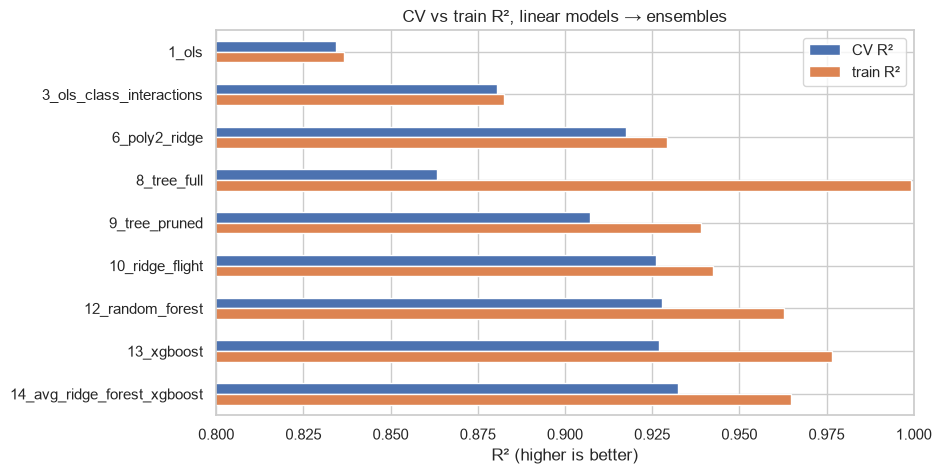

In [12]:
log = pd.read_csv(config.results_dir(TASK) / "experiments.csv")
table = (log[["model", "params", "r2_mean", "r2_std", "train_r2_mean", "rmse_mean", "public_lb"]]
         .sort_values("r2_mean", ascending=False).reset_index(drop=True))
display(table.round(4))

main = ["1_ols", "3_ols_class_interactions", "6_poly2_ridge", "8_tree_full", "9_tree_pruned", "10_ridge_flight",
        "12_random_forest", "13_xgboost", "14_avg_ridge_forest_xgboost"]
plot = table.set_index("model").loc[main, ["r2_mean", "train_r2_mean"]]
ax = plot.rename(columns={"r2_mean": "CV R²", "train_r2_mean": "train R²"}).plot.barh(figsize=(9, 5))
ax.set(xlim=(0.8, 1.0), xlabel="R² (higher is better)", ylabel="", title="CV vs train R², linear models → ensembles")
ax.invert_yaxis()
plt.savefig(FIG_DIR / "ensembles_r2.png", dpi=120, bbox_inches="tight")
plt.show()

## Final submission

In [13]:
final = VotingRegressor([(p, best_models[p]) for p in ["ridge", "forest", "xgboost"]])
path, sub = evaluate.make_submission(final, X, y, X_test, test_ids, sample_sub, TASK, "14_avg_ridge_forest_xgboost", date="2026-10-11")
print("saved:", path.name)
print(sub["price"].describe().round(0).to_string())

saved: 2026-10-11_14_avg_ridge_forest_xgboost.csv
count      3898.0
mean      29694.0
std       38022.0
min        3462.0
25%        7479.0
50%       10210.0
75%       36677.0
max      229672.0


- Submitted `14_avg_ridge_forest_xgboost`: public score **0.96080**.

## Summary
| Model | CV R² | Public |
|---|---|---|
| Ridge + flight × class | 0.9262 | 0.94922 |
| Random Forest | 0.9278 | |
| XGBoost | 0.9271 | |
| **Average of Ridge + RF + XGBoost** | **0.9325** | **0.96080** |